# Telecom Churn Risk Model — cost-aware, calibrated and explainable
**Scenario:** a fictional Chennai telecom operator is losing prepaid and postpaid customers. This notebook builds a churn model its retention team can act on.

**Pipeline at a glance**

| # | Step | Brief requirement covered |
|---|------|---------------------------|
| 1 | Setup, data loading | public dataset (~7,000 customers) |
| 2 | Data audit and cleaning, leakage audit | blank `TotalCharges`, inconsistent labels, imbalance, leaky features |
| 3 | Stratified train/test split | held-out test set |
| 4 | Leak-free `Pipeline` + `ColumnTransformer` | cleaning, encoding, scaling inside CV |
| 5 | 13 engineered features + ablation | at least 8 features, value tested through ablation |
| 6 | Tuning: Logistic Regression, Random Forest, Gradient Boosting | stratified 5-fold CV, class weights |
| 7 | Comparison table | precision, recall, ROC AUC, PR AUC |
| 8 | Probability calibration and cost-based threshold | FN costs 5x FP |
| 9 | Test evaluation, deciles, lift chart | ROC AUC >= 0.84, lift in top two deciles |
| 10 | SHAP (global + individual) and 3 retention segments | stretch requirement |
| 11 | Save model, reload check, checklist | deliverables |

**How to run:** `Runtime > Run all`. No file upload is needed because the dataset is downloaded automatically (an upload prompt appears only if the download fails). Total run time is roughly 10-15 minutes on a free Colab CPU. All outputs are written to `churn_outputs/`.

## 1. Setup

In [1]:
import sys, subprocess, importlib

def _ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure("shap")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.1 Shared code module
Custom classes (cleaning function, feature engineer, class-weighted gradient boosting) are written to `churn_pipeline.py` and imported from there. This is deliberate: a model pickled from a notebook's `__main__` can only be reloaded inside that notebook, whereas a model that references a real module can be reloaded anywhere the file is present.

In [2]:
%%writefile churn_pipeline.py
"""
churn_pipeline.py
Shared, importable building blocks for the Telecom Churn Risk Model.

Keeping the custom classes in a real module (instead of the notebook's __main__)
means the saved model (churn_model.joblib) can be loaded in ANY Python session
as long as this file sits next to it.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# --------------------------------------------------------------------------
# Constants
# --------------------------------------------------------------------------
ID_COLS = ["customerID", "CustomerID", "Customer ID"]
TARGET_CANDIDATES = ["Churn", "Churn Label"]
# Columns that only exist AFTER a customer has churned (or are model outputs
# built from the outcome). They would leak the future into the model.
LEAKAGE_PATTERNS = ("churn label", "churn score", "churn reason", "churn category",
                    "churn value", "cltv", "customer status", "satisfaction score")

ADDON_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
PROTECT_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
STREAM_COLS = ["StreamingTV", "StreamingMovies"]

_YES = {"yes", "y", "true", "1"}
_NO = {"no", "n", "false", "0"}
_NO_SERVICE = {"no internet service", "no phone service"}


# --------------------------------------------------------------------------
# Deterministic cleaning (no statistics learned from data -> safe before split)
# --------------------------------------------------------------------------
def _unify_case(s: pd.Series) -> pd.Series:
    """Collapse spelling/case/whitespace variants of the same label."""
    key = s.str.lower().str.replace(r"\s+", " ", regex=True)
    canon = s.groupby(key).agg(lambda x: x.value_counts().index[0])
    return key.map(canon)


def clean_telco(df_raw: pd.DataFrame):
    """Return (X, y, ids). y is None when the target column is absent (scoring)."""
    df = df_raw.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # 1) whitespace -> NaN for every text column
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            s = df[c].astype(str).str.strip()
            df[c] = s.mask(s.isin(["", "nan", "NaN", "None", "NA", "N/A"]), np.nan)

    # 2) identifiers / target / leakage columns
    id_col = next((c for c in ID_COLS if c in df.columns), None)
    ids = df[id_col].copy() if id_col else pd.Series(np.arange(len(df)), index=df.index)
    target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
    y = None
    if target_col is not None:
        y = df[target_col].str.lower().isin(_YES).astype(int)
    drop = set([id_col] if id_col else [])
    if target_col:
        drop.add(target_col)
    for c in df.columns:
        low = c.lower().replace("_", " ")
        if c != target_col and any(p in low for p in LEAKAGE_PATTERNS):
            drop.add(c)
    df = df.drop(columns=[c for c in drop if c in df.columns])

    # 3) numeric columns
    for c in ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # 4) inconsistent category labels
    for c in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
        low = df[c].str.lower()
        vals = set(low.dropna().unique())
        if vals and vals <= (_YES | _NO | _NO_SERVICE):
            # "No internet service" / "No phone service" are just another way
            # of saying "No" (the real information lives in InternetService /
            # PhoneService), so they are merged into "No".
            df[c] = low.map(lambda v: np.nan if pd.isna(v) else ("Yes" if v in _YES else "No"))
        else:
            df[c] = _unify_case(df[c])

    # 5) blank TotalCharges belong to brand-new customers (tenure == 0): nothing
    #    has been billed yet, so the true value is 0 (business rule, not a guess)
    if {"TotalCharges", "tenure"} <= set(df.columns):
        df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0
    return df, y, ids


# --------------------------------------------------------------------------
# Feature engineering (stateless transformer with switchable groups)
# --------------------------------------------------------------------------
FEATURE_GROUPS = {
    "tenure_lifecycle": ["tenure_band", "is_new_customer"],
    "spend_pattern": ["avg_monthly_spend", "charge_delta", "charge_per_service"],
    "service_bundle": ["addon_count", "protect_count", "stream_count"],
    "contract_payment": ["is_month_to_month", "is_electronic_check", "is_autopay"],
    "risk_combos": ["fiber_no_support", "family_score"],
}
ALL_GROUPS = tuple(FEATURE_GROUPS)
N_ENGINEERED = sum(len(v) for v in FEATURE_GROUPS.values())


def _yes(df, col):
    return (df[col] == "Yes").astype(int) if col in df.columns else 0


class ChurnFeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds engineered columns. `groups=None` -> all groups, `groups=()` -> none."""

    def __init__(self, groups=None):
        self.groups = groups

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        groups = ALL_GROUPS if self.groups is None else tuple(self.groups)
        tenure = X["tenure"].astype(float)
        mc = X["MonthlyCharges"].astype(float)
        tc = pd.to_numeric(X["TotalCharges"], errors="coerce")
        avg_spend = (tc / tenure.where(tenure > 0)).fillna(mc)          # history-based price
        addon = sum(_yes(X, c) for c in ADDON_COLS)
        n_services = addon + _yes(X, "PhoneService") + (X["InternetService"] != "No").astype(int)

        if "tenure_lifecycle" in groups:
            X["tenure_band"] = pd.cut(tenure, [-1, 6, 12, 24, 48, np.inf],
                                      labels=["0-6m", "7-12m", "13-24m", "25-48m", "49m+"]).astype(str)
            X["is_new_customer"] = (tenure <= 6).astype(int)
        if "spend_pattern" in groups:
            X["avg_monthly_spend"] = avg_spend
            X["charge_delta"] = mc - avg_spend                          # >0 : paying more than historically
            X["charge_per_service"] = mc / (1 + n_services)
        if "service_bundle" in groups:
            X["addon_count"] = addon
            X["protect_count"] = sum(_yes(X, c) for c in PROTECT_COLS)
            X["stream_count"] = sum(_yes(X, c) for c in STREAM_COLS)
        if "contract_payment" in groups:
            X["is_month_to_month"] = (X["Contract"] == "Month-to-month").astype(int)
            X["is_electronic_check"] = (X["PaymentMethod"] == "Electronic check").astype(int)
            X["is_autopay"] = X["PaymentMethod"].str.contains("automatic", case=False, na=False).astype(int)
        if "risk_combos" in groups:
            X["fiber_no_support"] = ((X["InternetService"] == "Fiber optic")
                                     & (X["TechSupport"] == "No")
                                     & (X["OnlineSecurity"] == "No")).astype(int)
            X["family_score"] = _yes(X, "Partner") + _yes(X, "Dependents")
        return X


# --------------------------------------------------------------------------
# Pre-processing (ColumnTransformer) and model pipeline builder
# --------------------------------------------------------------------------
def numeric_columns(df):
    return [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]


def categorical_columns(df):
    return [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]


def make_preprocessor(scale=True):
    num = Pipeline([("imp", SimpleImputer(strategy="median")),
                    ("sc", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, numeric_columns),
                              ("cat", cat, categorical_columns)],
                             verbose_feature_names_out=False)


def build_pipeline(model, groups=None, scale=True):
    return Pipeline([("fe", ChurnFeatureEngineer(groups=groups)),
                     ("prep", make_preprocessor(scale)),
                     ("clf", model)])


# --------------------------------------------------------------------------
# Gradient boosting with class_weight support (sklearn's GBM only takes sample_weight)
# --------------------------------------------------------------------------
class BalancedGB(GradientBoostingClassifier):
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3,
                 min_samples_leaf=1, subsample=1.0, max_features=None,
                 class_weight=None, random_state=None):
        super().__init__(n_estimators=n_estimators, learning_rate=learning_rate,
                         max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                         subsample=subsample, max_features=max_features,
                         random_state=random_state)
        self.class_weight = class_weight

    def fit(self, X, y, sample_weight=None):
        if self.class_weight is not None:
            cw = compute_sample_weight(self.class_weight, y)
            sample_weight = cw if sample_weight is None else cw * sample_weight
        return super().fit(X, y, sample_weight=sample_weight)

Overwriting churn_pipeline.py


In [3]:
import os, json, time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap, sklearn
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, roc_curve,
                             confusion_matrix)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict, cross_validate)

import churn_pipeline as cp
importlib.reload(cp)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
OUT = "churn_outputs"
os.makedirs(OUT, exist_ok=True)

COST_FP = 1.0   # a wasted retention offer (customer would have stayed anyway)
COST_FN = 5.0   # a missed churner costs five times a wasted offer
RESULTS = {}    # everything we report is collected here and saved as results.json

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sklearn {sklearn.__version__} | shap {shap.__version__}")

python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | sklearn 1.8.0 | shap 0.54.1


## 2. Load the data
The public **Telco Customer Churn** dataset (7,043 customers, 21 columns) is used. The loader tries a local copy first, then two public mirrors, and finally falls back to a manual upload.

In [4]:
LOCAL_CANDIDATES = ["Telco-Customer-Churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.csv",
                    "/content/Telco-Customer-Churn.csv", "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"]
DATA_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

def load_data():
    for p in LOCAL_CANDIDATES:
        if os.path.exists(p):
            return pd.read_csv(p), p
    for url in DATA_URLS:
        try:
            return pd.read_csv(url), url
        except Exception as e:
            print("download failed:", url, "->", type(e).__name__)
    try:                                           # last resort: manual upload in Colab
        from google.colab import files
        print("Please upload the Telco churn CSV (Telco-Customer-Churn.csv).")
        up = files.upload()
        name = next(iter(up))
        return pd.read_csv(name), name
    except ImportError:
        raise FileNotFoundError("Place Telco-Customer-Churn.csv next to this notebook.")

raw, source = load_data()
print("loaded from:", source)
print("raw shape  :", raw.shape)
raw.head()

loaded from: Telco-Customer-Churn.csv
raw shape  : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data audit
Before touching anything, check the problems named in the brief: blank `TotalCharges`, inconsistent category labels, class imbalance and possible leakage.

In [5]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "n_unique": raw.nunique(),
                      "n_null": raw.isna().sum(),
                      "n_blank_text": [(raw[c].astype(str).str.strip() == "").sum() for c in raw.columns]})
display(audit)

blank_tc = raw["TotalCharges"].astype(str).str.strip() == ""
print(f"\nBlank TotalCharges rows: {blank_tc.sum()}  | their tenure values: {sorted(raw.loc[blank_tc, 'tenure'].unique())}")
print("duplicate customerIDs:", raw["customerID"].duplicated().sum())

print("\nInconsistent / redundant labels (low-cardinality text columns):")
for c in raw.columns:
    if raw[c].dtype == object or str(raw[c].dtype).startswith("str"):
        u = raw[c].dropna().unique()
        if len(u) <= 4:
            print(f"  {c:18s} {sorted(map(str, u))}")

vc = raw["Churn"].value_counts()
print(f"\nClass balance -> No: {vc['No']} ({vc['No']/len(raw):.1%}) | Yes: {vc['Yes']} ({vc['Yes']/len(raw):.1%})  "
      f"(about 1 churner in {len(raw)/vc['Yes']:.1f})")
RESULTS["raw_rows"] = int(len(raw)); RESULTS["raw_cols"] = int(raw.shape[1])
RESULTS["blank_total_charges"] = int(blank_tc.sum())
RESULTS["churn_rate"] = float((raw["Churn"] == "Yes").mean())

,dtype,n_unique,n_null,n_blank_text
customerID,str,7043,0,0
gender,str,2,0,0
SeniorCitizen,int64,2,0,0
Partner,str,2,0,0
Dependents,str,2,0,0
tenure,int64,73,0,0
PhoneService,str,2,0,0
MultipleLines,str,3,0,0
InternetService,str,3,0,0
OnlineSecurity,str,3,0,0



Blank TotalCharges rows: 11  | their tenure values: [np.int64(0)]
duplicate customerIDs: 0

Inconsistent / redundant labels (low-cardinality text columns):
  gender             ['Female', 'Male']
  Partner            ['No', 'Yes']
  Dependents         ['No', 'Yes']
  PhoneService       ['No', 'Yes']
  MultipleLines      ['No', 'No phone service', 'Yes']
  InternetService    ['DSL', 'Fiber optic', 'No']
  OnlineSecurity     ['No', 'No internet service', 'Yes']
  OnlineBackup       ['No', 'No internet service', 'Yes']
  DeviceProtection   ['No', 'No internet service', 'Yes']
  TechSupport        ['No', 'No internet service', 'Yes']
  StreamingTV        ['No', 'No internet service', 'Yes']
  StreamingMovies    ['No', 'No internet service', 'Yes']
  Contract           ['Month-to-month', 'One year', 'Two year']
  PaperlessBilling   ['No', 'Yes']
  PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
  Churn              ['No', 'Yes

## 4. Cleaning (deterministic only) and leakage audit
`clean_telco()` (see `churn_pipeline.py`) only applies **rules that learn nothing from the data**, so it is safe to run before the train/test split:

* trims whitespace, turns blank strings into missing values
* converts `TotalCharges` to numeric; the 11 blanks are brand-new customers (`tenure = 0`), so the correct value is 0
* merges `"No internet service"` / `"No phone service"` into `"No"` (the information already sits in `InternetService` / `PhoneService`), and unifies case/spelling variants
* drops the identifier and any column that only exists after churn (`Churn Label/Score/Reason/Category/Value`, `CLTV`, `Customer Status`, ...). The standard file has none of these, but the guard makes the notebook safe on the extended IBM version.

Everything that **learns from data** (imputation, scaling, one-hot encoding) lives inside the sklearn `Pipeline`, so it is re-fitted on the training part of every CV fold and never sees validation or test rows.

In [6]:
X_all, y_all, ids = cp.clean_telco(raw)
print("clean feature matrix:", X_all.shape, "| target mean:", round(y_all.mean(), 4))
print("missing values after cleaning:", int(X_all.isna().sum().sum()))
for c in ["MultipleLines", "OnlineSecurity", "InternetService", "Contract", "PaymentMethod"]:
    print(f"  {c:16s}", sorted(X_all[c].unique()))
X_all.head()

clean feature matrix: (7043, 19) | target mean: 0.2654
missing values after cleaning: 0
  MultipleLines    ['No', 'Yes']
  OnlineSecurity   ['No', 'Yes']
  InternetService  ['DSL', 'Fiber optic', 'No']
  Contract         ['Month-to-month', 'One year', 'Two year']
  PaymentMethod    ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [7]:
# ---- Leakage audit: how well can ONE column predict churn on its own? ----------
# A single column with ROC AUC > 0.90 would be a red flag (it would usually encode the outcome).
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score

rows = []
cv_quick = StratifiedKFold(5, shuffle=True, random_state=SEED)
for c in X_all.columns:
    is_num = pd.api.types.is_numeric_dtype(X_all[c])
    step = (Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]) if is_num else
            Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                      ("o", OneHotEncoder(handle_unknown="ignore"))]))
    pipe = Pipeline([("t", ColumnTransformer([("c", step, [c])])), ("m", LogisticRegression(max_iter=1000))])
    auc = cross_val_score(pipe, X_all, y_all, cv=cv_quick, scoring="roc_auc").mean()
    rows.append((c, auc))
leak = pd.DataFrame(rows, columns=["feature", "single_feature_cv_auc"]).sort_values("single_feature_cv_auc", ascending=False)
leak["flag"] = np.where(leak["single_feature_cv_auc"] > 0.90, "SUSPICIOUS", "ok")
display(leak.head(8).round(4))
print("columns flagged as suspicious (>0.90):", int((leak["flag"] == "SUSPICIOUS").sum()))

# TotalCharges is (almost) tenure x MonthlyCharges: a cumulative billing figure, available at scoring time
corr = np.corrcoef(X_all["TotalCharges"], X_all["tenure"] * X_all["MonthlyCharges"])[0, 1]
print(f"corr(TotalCharges, tenure x MonthlyCharges) = {corr:.3f} -> kept, it is known at scoring time; "
      "its redundancy with tenure is handled by regularisation and by the ablation study below.")
leak.to_csv(f"{OUT}/leakage_audit.csv", index=False)
RESULTS["leakage_flagged"] = int((leak["flag"] == "SUSPICIOUS").sum())
RESULTS["leakage_max_auc"] = float(leak["single_feature_cv_auc"].max())
RESULTS["leakage_top_feature"] = str(leak.iloc[0]["feature"])

,feature,single_feature_cv_auc,flag
4,tenure,0.7397,ok
14,Contract,0.7391,ok
7,InternetService,0.6953,ok
16,PaymentMethod,0.6712,ok
18,TotalCharges,0.6504,ok
17,MonthlyCharges,0.6211,ok
15,PaperlessBilling,0.6067,ok
8,OnlineSecurity,0.5877,ok


columns flagged as suspicious (>0.90): 0
corr(TotalCharges, tenure x MonthlyCharges) = 1.000 -> kept, it is known at scoring time; its redundancy with tenure is handled by regularisation and by the ablation study below.


### 4.1 Quick EDA: where does churn concentrate?

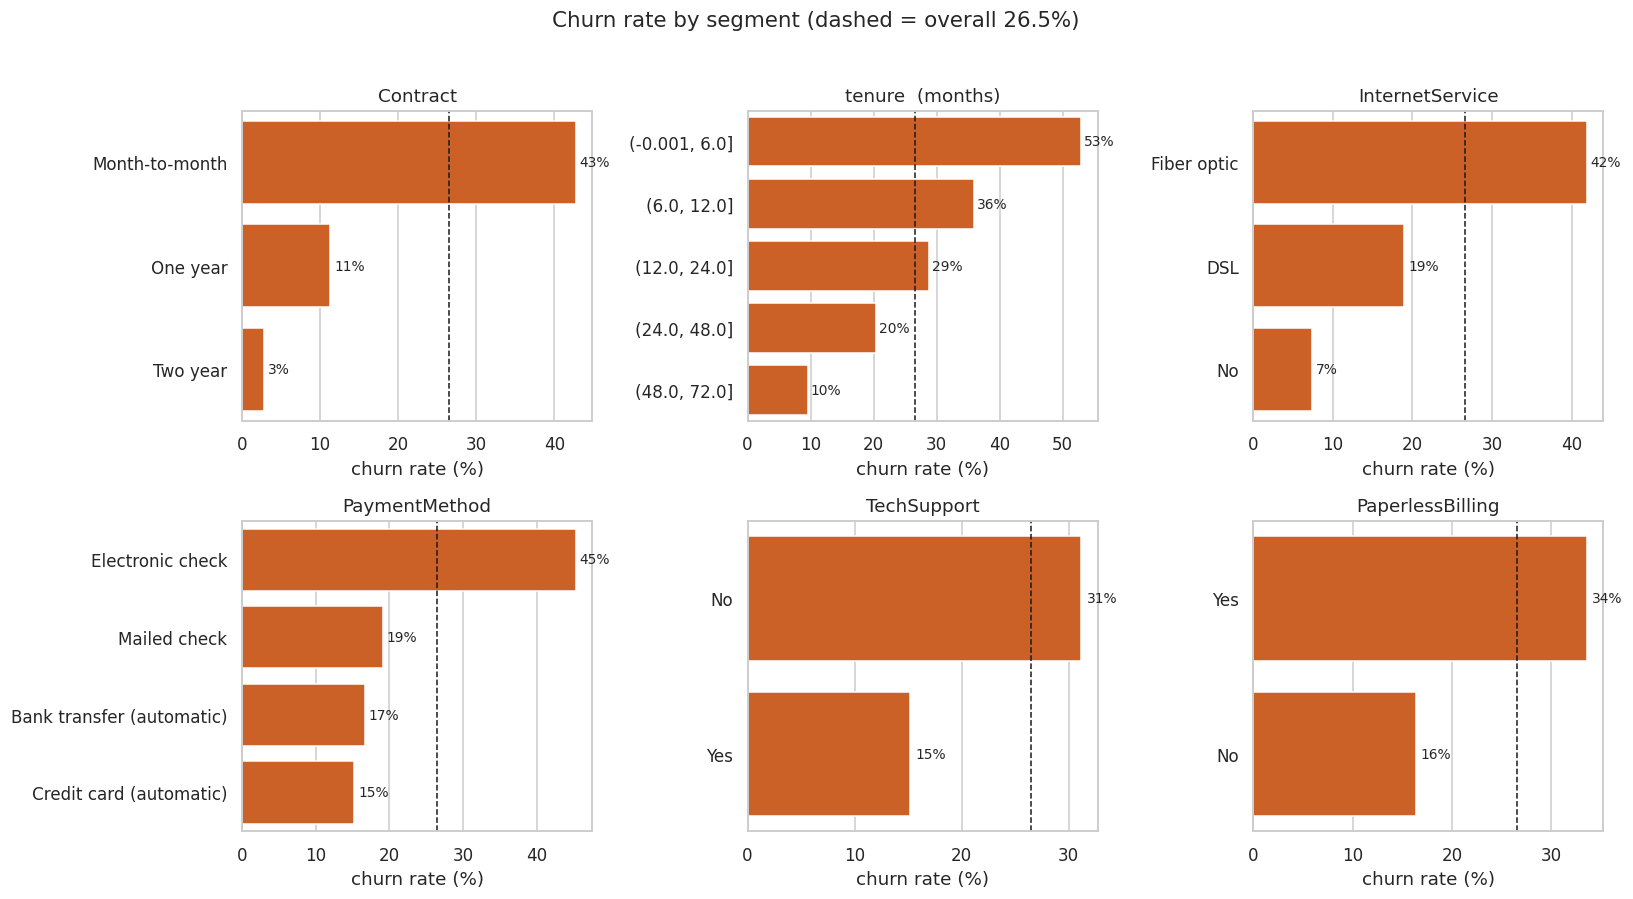

In [8]:
eda = X_all.copy(); eda["churn"] = y_all.values
panels = [("Contract", None), ("tenure", [0, 6, 12, 24, 48, 72]), ("InternetService", None),
          ("PaymentMethod", None), ("TechSupport", None), ("PaperlessBilling", None)]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
base = y_all.mean()
for ax, (col, bins) in zip(axes.ravel(), panels):
    s = pd.cut(eda[col], bins, include_lowest=True) if bins else eda[col]
    r = eda.groupby(s, observed=True)["churn"].mean().sort_values(ascending=False) if not bins else eda.groupby(s, observed=True)["churn"].mean()
    r.index = r.index.astype(str)
    sns.barplot(x=r.values * 100, y=r.index, ax=ax, color="#E8590C")
    ax.axvline(base * 100, color="k", ls="--", lw=1); ax.set_xlabel("churn rate (%)"); ax.set_ylabel("")
    ax.set_title(col + ("  (months)" if bins else ""))
    for i, v in enumerate(r.values * 100): ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9)
fig.suptitle(f"Churn rate by segment (dashed = overall {base:.1%})", y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT}/eda_churn_rates.png"); plt.show()

## 5. Stratified train / test split
20% of customers are locked away as a **held-out test set** that is used once, for the final evaluation. All tuning, calibration and threshold selection use the 80% training part only.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print(f"train: {X_train.shape}  churn rate {y_train.mean():.4f}")
print(f"test : {X_test.shape}   churn rate {y_test.mean():.4f}")
RESULTS.update(n_train=int(len(X_train)), n_test=int(len(X_test)),
               train_churn_rate=float(y_train.mean()), test_churn_rate=float(y_test.mean()))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train: (5634, 19)  churn rate 0.2654
test : (1409, 19)   churn rate 0.2654


## 6. Feature engineering and ablation
Thirteen engineered features in five business-meaningful groups:

| Group | Features | Hypothesis |
|-------|----------|-----------|
| `tenure_lifecycle` | `tenure_band`, `is_new_customer` | churn risk is non-linear in customer age; the first months are fragile |
| `spend_pattern` | `avg_monthly_spend`, `charge_delta`, `charge_per_service` | paying more than you used to, or a lot per service, drives exits |
| `service_bundle` | `addon_count`, `protect_count`, `stream_count` | more bundled services means higher switching costs |
| `contract_payment` | `is_month_to_month`, `is_electronic_check`, `is_autopay` | low-commitment contracts and manual payment are easy to leave |
| `risk_combos` | `fiber_no_support`, `family_score` | premium fibre without support, and households with partner/dependents |

**Ablation** (Logistic Regression, repeated 5x3 stratified CV on the training set only): baseline without any engineered feature, each group added alone, all groups together, and each group removed from the full set.

In [10]:
fe_demo = cp.ChurnFeatureEngineer().fit(X_train)
new_cols = [c for c in fe_demo.transform(X_train.head()).columns if c not in X_train.columns]
print(f"{len(new_cols)} engineered features:", new_cols)
assert len(new_cols) >= 8

13 engineered features: ['tenure_band', 'is_new_customer', 'avg_monthly_spend', 'charge_delta', 'charge_per_service', 'addon_count', 'protect_count', 'stream_count', 'is_month_to_month', 'is_electronic_check', 'is_autopay', 'fiber_no_support', 'family_score']


,setting,roc_auc,roc_auc_std,pr_auc,d_roc_auc_vs_baseline,d_pr_auc_vs_baseline,d_roc_auc_vs_all
0,Baseline: raw features only,0.8454,0.0116,0.6596,0.0000,0.0000,-0.0022
1,+ only tenure_lifecycle,0.8481,0.0118,0.6636,0.0027,0.0040,0.0005
2,+ only spend_pattern,0.8449,0.0115,0.6581,-0.0005,-0.0016,-0.0027
3,+ only service_bundle,0.8454,0.0116,0.6595,0.0000,-0.0001,-0.0022
4,+ only contract_payment,0.8454,0.0116,0.6592,0.0000,-0.0005,-0.0022
5,+ only risk_combos,0.8452,0.0116,0.6595,-0.0001,-0.0002,-0.0023
6,All 5 groups (13 features),0.8476,0.0117,0.6619,0.0022,0.0022,0.0000
7,All minus tenure_lifecycle,0.8449,0.0115,0.6575,-0.0005,-0.0021,-0.0027
8,All minus spend_pattern,0.8479,0.0118,0.6634,0.0025,0.0038,0.0004
9,All minus service_bundle,0.8476,0.0117,0.6618,0.0022,0.0021,0.0000


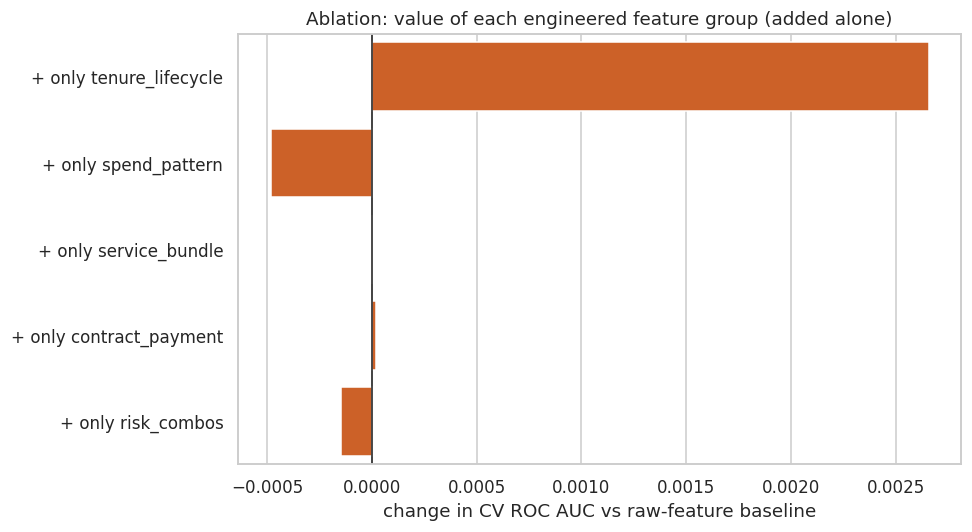

In [11]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
SC = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

def ablation_score(groups, label):
    pipe = cp.build_pipeline(LogisticRegression(C=0.1, max_iter=3000), groups=groups)
    r = cross_validate(pipe, X_train, y_train, cv=rcv, scoring=SC, n_jobs=-1)
    return {"setting": label, "roc_auc": r["test_roc_auc"].mean(), "roc_auc_std": r["test_roc_auc"].std(),
            "pr_auc": r["test_pr_auc"].mean()}

rows = [ablation_score((), "Baseline: raw features only")]
for g in cp.ALL_GROUPS:
    rows.append(ablation_score((g,), f"+ only {g}"))
rows.append(ablation_score(None, "All 5 groups (13 features)"))
for g in cp.ALL_GROUPS:
    rows.append(ablation_score(tuple(x for x in cp.ALL_GROUPS if x != g), f"All minus {g}"))

abl = pd.DataFrame(rows)
b_auc, b_pr = abl.loc[0, "roc_auc"], abl.loc[0, "pr_auc"]
abl["d_roc_auc_vs_baseline"] = abl["roc_auc"] - b_auc
abl["d_pr_auc_vs_baseline"] = abl["pr_auc"] - b_pr
all_auc = abl.loc[abl.setting.str.startswith("All 5"), "roc_auc"].iloc[0]
abl["d_roc_auc_vs_all"] = abl["roc_auc"] - all_auc
abl.round(4).to_csv(f"{OUT}/ablation_table.csv", index=False)
display(abl.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = abl.iloc[1:6].copy()
sns.barplot(data=plot_df, y="setting", x="d_roc_auc_vs_baseline", color="#E8590C", ax=ax)
ax.axvline(0, color="k", lw=1); ax.set_xlabel("change in CV ROC AUC vs raw-feature baseline"); ax.set_ylabel("")
ax.set_title("Ablation: value of each engineered feature group (added alone)")
plt.tight_layout(); plt.savefig(f"{OUT}/ablation_chart.png"); plt.show()
RESULTS["ablation"] = abl.round(5).to_dict(orient="records")
RESULTS["fe_gain_roc"] = float(all_auc - b_auc); RESULTS["fe_gain_pr"] = float(abl.loc[abl.setting.str.startswith("All 5"), "pr_auc"].iloc[0] - b_pr)

## 7. Model training and tuning
Three model families, each inside the same leak-free pipeline (`fe -> ColumnTransformer -> classifier`), tuned with `RandomizedSearchCV` over **stratified 5-fold CV** with ROC AUC as the objective (PR AUC recorded alongside). Class imbalance is handled through **class weights**, and whether to use them is itself a tuned hyper-parameter.

In [12]:
searches = {
    "Logistic Regression": dict(
        pipe=cp.build_pipeline(LogisticRegression(max_iter=5000, random_state=SEED), scale=True),
        space={"clf__C": loguniform(1e-3, 1e1), "clf__class_weight": [None, "balanced"]}, n_iter=20),
    "Random Forest": dict(
        pipe=cp.build_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1), scale=False),
        space={"clf__n_estimators": randint(200, 500), "clf__max_depth": [4, 6, 8, 10, 14, None],
               "clf__min_samples_leaf": randint(3, 25), "clf__max_features": ["sqrt", 0.2, 0.4],
               "clf__class_weight": ["balanced", "balanced_subsample"]}, n_iter=12),
    "Gradient Boosting": dict(
        pipe=cp.build_pipeline(cp.BalancedGB(random_state=SEED), scale=False),
        space={"clf__n_estimators": randint(100, 400), "clf__learning_rate": loguniform(0.01, 0.2),
               "clf__max_depth": randint(2, 4), "clf__min_samples_leaf": randint(5, 40),
               "clf__subsample": uniform(0.6, 0.4), "clf__max_features": ["sqrt", 0.5, None],
               "clf__class_weight": [None, "balanced"]}, n_iter=12),
}

fitted, search_tables = {}, {}
for name, cfg in searches.items():
    t0 = time.time()
    rs = RandomizedSearchCV(cfg["pipe"], cfg["space"], n_iter=cfg["n_iter"], cv=cv5, scoring=SC,
                            refit="roc_auc", n_jobs=-1, random_state=SEED, return_train_score=False)
    rs.fit(X_train, y_train)
    fitted[name] = rs
    search_tables[name] = pd.DataFrame(rs.cv_results_).sort_values("rank_test_roc_auc")
    i = rs.best_index_
    print(f"{name:20s} CV ROC AUC {rs.cv_results_['mean_test_roc_auc'][i]:.4f} "
          f"(+/- {rs.cv_results_['std_test_roc_auc'][i]:.4f}) | CV PR AUC {rs.cv_results_['mean_test_pr_auc'][i]:.4f} "
          f"| {time.time()-t0:.0f}s")
    print("   best params:", {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

RESULTS["best_params"] = {n: {k.replace("clf__", ""): (float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v))
                              for k, v in rs.best_params_.items()} for n, rs in fitted.items()}

Logistic Regression  CV ROC AUC 0.8470 (+/- 0.0113) | CV PR AUC 0.6617 | 10s
   best params: {'C': np.float64(7.8528), 'class_weight': None}


Random Forest        CV ROC AUC 0.8471 (+/- 0.0098) | CV PR AUC 0.6599 | 125s
   best params: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 19, 'n_estimators': 258}


Gradient Boosting    CV ROC AUC 0.8476 (+/- 0.0120) | CV PR AUC 0.6617 | 79s
   best params: {'class_weight': None, 'learning_rate': np.float64(0.0249), 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 29, 'n_estimators': 148, 'subsample': np.float64(0.8099)}


## 8. Model comparison
For every tuned model the table shows cross-validated scores (training data) and held-out test scores. **Model selection uses CV only**; the test set is not used to pick the winner.

Two operating points are shown. `@0.50` is the conventional threshold. `@cost` is the threshold that minimises expected cost on **out-of-fold training predictions** (a miss costs 5 and a wasted offer costs 1); it is chosen without looking at the test set.

,Model,CV ROC AUC,CV ROC AUC std,CV PR AUC,Test ROC AUC,Test PR AUC,Precision @0.50,Recall @0.50,F1 @0.50,Cost threshold,Precision @cost,Recall @cost,Test cost @cost
0,Logistic Regression,0.8470,0.0113,0.6617,0.8444,0.6492,0.6586,0.5107,0.5753,0.1900,0.4701,0.8824,592.0000
1,Random Forest,0.8471,0.0098,0.6599,0.8463,0.6553,0.5385,0.7861,0.6391,0.3800,0.4775,0.8529,624.0000
2,Gradient Boosting,0.8476,0.0120,0.6617,0.8462,0.6601,0.6679,0.4679,0.5503,0.1600,0.4382,0.9198,591.0000
3,Baseline (prior only),0.5000,0.0000,0.2654,0.5000,0.2654,0.0000,0.0000,0.0000,nan,nan,nan,1870.0000



Selected model (highest CV ROC AUC): Gradient Boosting


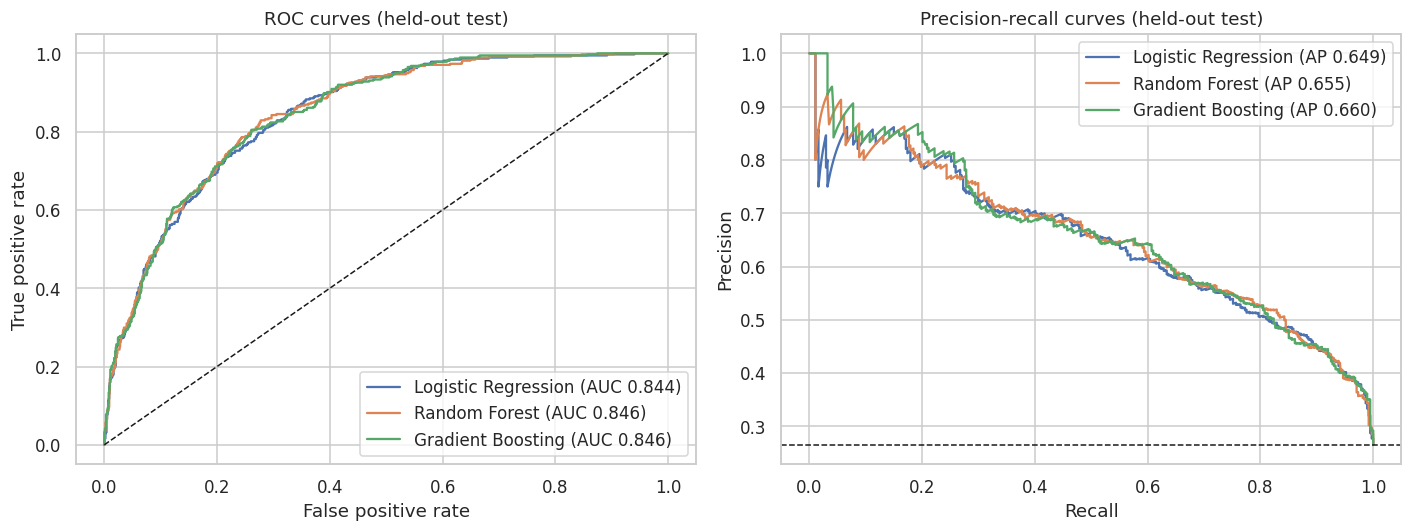

In [13]:
thr_grid = np.round(np.arange(0.02, 0.98, 0.01), 2)

def cost_at(y_true, p, thr):
    pred = (p >= thr)
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    return COST_FP * fp + COST_FN * fn

def best_threshold(y_true, p):
    y_true = np.asarray(y_true)
    costs = np.array([cost_at(y_true, p, t) for t in thr_grid])
    return float(thr_grid[costs.argmin()]), costs

def ece_score(y_true, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(np.asarray(y_true)[m].mean() - p[m].mean())
    return float(e)

def prf(y_true, p, thr):
    pred = (p >= thr).astype(int)
    return (precision_score(y_true, pred, zero_division=0), recall_score(y_true, pred), f1_score(y_true, pred))

rows, oof_raw = [], {}
for name, rs in fitted.items():
    i = rs.best_index_; best = rs.best_estimator_
    oof = cross_val_predict(clone(best), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
    oof_raw[name] = oof
    thr_c, _ = best_threshold(y_train, oof)
    p_test = best.predict_proba(X_test)[:, 1]
    p50, r50, f50 = prf(y_test, p_test, 0.5)
    pc, rc, fc = prf(y_test, p_test, thr_c)
    rows.append({"Model": name,
                 "CV ROC AUC": rs.cv_results_["mean_test_roc_auc"][i], "CV ROC AUC std": rs.cv_results_["std_test_roc_auc"][i],
                 "CV PR AUC": rs.cv_results_["mean_test_pr_auc"][i],
                 "Test ROC AUC": roc_auc_score(y_test, p_test), "Test PR AUC": average_precision_score(y_test, p_test),
                 "Precision @0.50": p50, "Recall @0.50": r50, "F1 @0.50": f50,
                 "Cost threshold": thr_c, "Precision @cost": pc, "Recall @cost": rc, "Test cost @cost": cost_at(y_test.values, p_test, thr_c)})

# reference point: a model that predicts the prior for everyone
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train); pd_ = dummy.predict_proba(X_test)[:, 1]
rows.append({"Model": "Baseline (prior only)", "CV ROC AUC": 0.5, "CV ROC AUC std": 0.0, "CV PR AUC": float(y_train.mean()),
             "Test ROC AUC": roc_auc_score(y_test, pd_), "Test PR AUC": average_precision_score(y_test, pd_),
             "Precision @0.50": 0.0, "Recall @0.50": 0.0, "F1 @0.50": 0.0, "Cost threshold": np.nan,
             "Precision @cost": np.nan, "Recall @cost": np.nan, "Test cost @cost": COST_FN * int(y_test.sum())})

comparison = pd.DataFrame(rows)
comparison.round(4).to_csv(f"{OUT}/comparison_table.csv", index=False)
display(comparison.round(4).style.format(precision=4).background_gradient(subset=["CV ROC AUC", "Test ROC AUC", "Test PR AUC"], cmap="Oranges"))

# selection on CV ROC AUC only (tie -> CV PR AUC)
cand = comparison[comparison.Model.isin(fitted)].sort_values(["CV ROC AUC", "CV PR AUC"], ascending=False)
best_name = cand.iloc[0]["Model"]; best_pipe = fitted[best_name].best_estimator_
print(f"\nSelected model (highest CV ROC AUC): {best_name}")
RESULTS["comparison"] = comparison.round(5).replace({np.nan: None}).to_dict(orient="records"); RESULTS["best_model"] = best_name

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, rs in fitted.items():
    p = rs.best_estimator_.predict_proba(X_test)[:, 1]; fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    from sklearn.metrics import precision_recall_curve
    pr, rc_, _ = precision_recall_curve(y_test, p); ax[1].plot(rc_, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (held-out test)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (held-out test)"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"{OUT}/model_comparison_curves.png"); plt.show()

## 9. Probability calibration and cost-based decision threshold
Class weights (and tree ensembles in general) distort predicted probabilities, but a cost-based threshold is only meaningful if "0.30" really means "30% chance of churn". The selected model is therefore wrapped in `CalibratedClassifierCV` (5-fold, cross-fitted) and the calibration method (sigmoid vs isotonic) is chosen by **out-of-fold Brier score** on the training set.

OOF Brier  uncalibrated: 0.1351 | sigmoid: 0.1345 | isotonic: 0.1344
chosen calibration method: isotonic


,Brier,ECE,ROC AUC,Mean predicted,Actual churn rate
Uncalibrated,0.1359,0.0327,0.8462,0.2670,0.2654
Calibrated (isotonic),0.1350,0.0224,0.8464,0.2669,0.2654


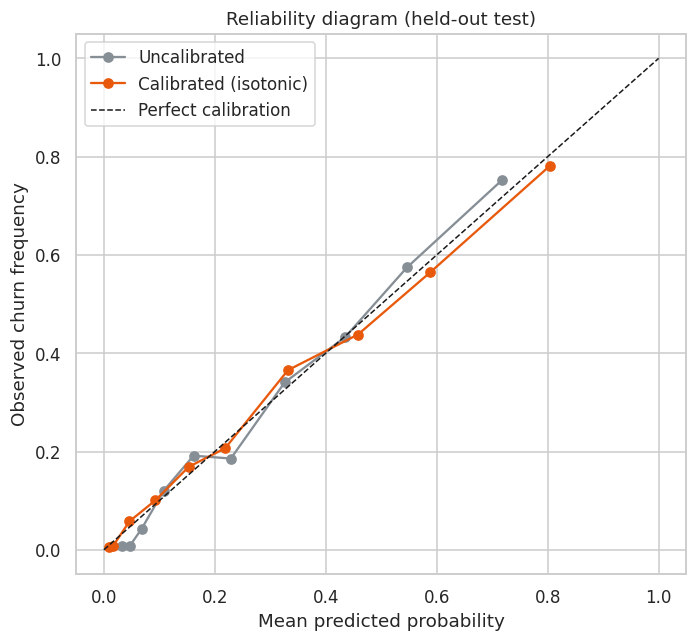

In [14]:
cal_scores = {}
oof_cal = {}
for method in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(clone(best_pipe), method=method, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1))
    oof_cal[method] = cross_val_predict(cal, X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
    cal_scores[method] = brier_score_loss(y_train, oof_cal[method])
raw_brier = brier_score_loss(y_train, oof_raw[best_name])
print(f"OOF Brier  uncalibrated: {raw_brier:.4f} | sigmoid: {cal_scores['sigmoid']:.4f} | isotonic: {cal_scores['isotonic']:.4f}")
cal_method = min(cal_scores, key=cal_scores.get)
print("chosen calibration method:", cal_method)

final_model = CalibratedClassifierCV(clone(best_pipe), method=cal_method,
                                     cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1)).fit(X_train, y_train)
p_test_raw = best_pipe.predict_proba(X_test)[:, 1]
p_test_cal = final_model.predict_proba(X_test)[:, 1]

cal_tbl = pd.DataFrame({"Brier": [brier_score_loss(y_test, p_test_raw), brier_score_loss(y_test, p_test_cal)],
                        "ECE": [ece_score(y_test, p_test_raw), ece_score(y_test, p_test_cal)],
                        "ROC AUC": [roc_auc_score(y_test, p_test_raw), roc_auc_score(y_test, p_test_cal)],
                        "Mean predicted": [p_test_raw.mean(), p_test_cal.mean()],
                        "Actual churn rate": [y_test.mean()] * 2}, index=["Uncalibrated", f"Calibrated ({cal_method})"])
display(cal_tbl.round(4)); cal_tbl.round(5).to_csv(f"{OUT}/calibration_table.csv")
RESULTS["calibration"] = {"method": cal_method, "oof_brier": {k: float(v) for k, v in cal_scores.items()}, "oof_brier_raw": float(raw_brier),
                          "test": cal_tbl.round(5).reset_index().rename(columns={"index": "model"}).to_dict(orient="records")}

fig, ax = plt.subplots(figsize=(6.5, 6))
for p, lab, col in [(p_test_raw, "Uncalibrated", "#868E96"), (p_test_cal, f"Calibrated ({cal_method})", "#E8590C")]:
    fp_, mp_ = calibration_curve(y_test, p, n_bins=10, strategy="quantile"); ax.plot(mp_, fp_, "o-", label=lab, color=col)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed churn frequency", title="Reliability diagram (held-out test)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/calibration_curve.png"); plt.show()

### 9.1 Choosing the threshold with the cost matrix
| | Predicted stay | Predicted churn |
|---|---|---|
| **Actually stays** | 0 | **1** (wasted offer) |
| **Actually churns** | **5** (missed churner) | 0 |

For perfectly calibrated probabilities the theoretical optimum is `FP / (FP + FN) = 1/6 = 0.167`. The threshold is selected empirically on **out-of-fold calibrated training predictions** and then applied once to the test set.

cost-optimal threshold (train OOF): 0.17 | theoretical for calibrated probs: 0.167


,Strategy,Contacted,TP,FP,FN,TN,Precision,Recall,Total cost,Saving vs contact nobody,Saving vs contact everybody
0,Contact nobody,0,0,0,374,1035,0.0000,0.0000,1870.0,0.0000,-0.8068
1,Contact everybody,1409,374,1035,0,0,0.2654,1.0000,1035.0,0.4465,0.0000
2,Model @ 0.50,310,205,105,169,930,0.6613,0.5481,950.0,0.4920,0.0821
3,Model @ 0.17 (cost-optimal),721,329,392,45,643,0.4563,0.8797,617.0,0.6701,0.4039


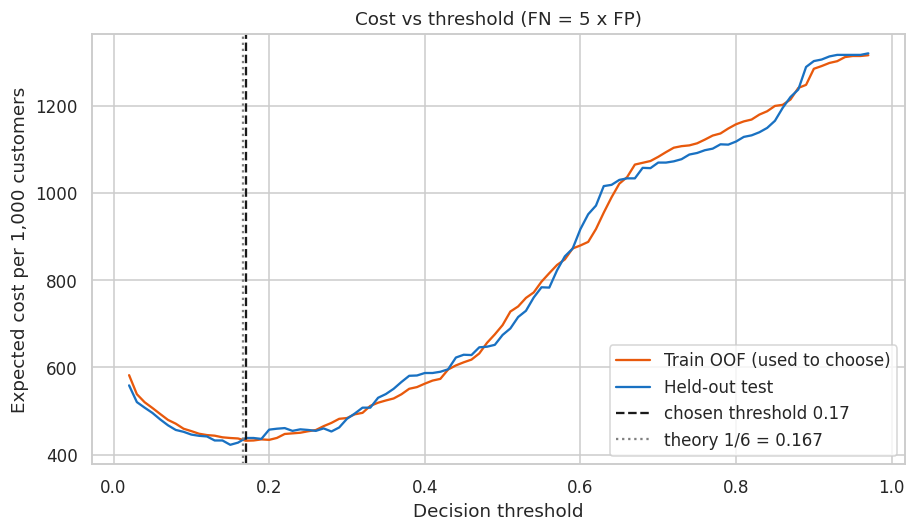

In [15]:
oof_p = oof_cal[cal_method]
thr, cost_curve = best_threshold(y_train, oof_p)
theory = COST_FP / (COST_FP + COST_FN)
print(f"cost-optimal threshold (train OOF): {thr:.2f} | theoretical for calibrated probs: {theory:.3f}")
RESULTS["threshold"] = thr; RESULTS["threshold_theory"] = theory

def strategy_row(name, pred, y_true):
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    tp = int(((pred == 1) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    return {"Strategy": name, "Contacted": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1), "Total cost": COST_FP * fp + COST_FN * fn}

yt = y_test.values
strats = [strategy_row("Contact nobody", np.zeros_like(yt), yt),
          strategy_row("Contact everybody", np.ones_like(yt), yt),
          strategy_row("Model @ 0.50", (p_test_cal >= 0.5).astype(int), yt),
          strategy_row(f"Model @ {thr:.2f} (cost-optimal)", (p_test_cal >= thr).astype(int), yt)]
strat = pd.DataFrame(strats)
strat["Saving vs contact nobody"] = 1 - strat["Total cost"] / strat.loc[0, "Total cost"]
strat["Saving vs contact everybody"] = 1 - strat["Total cost"] / strat.loc[1, "Total cost"]
display(strat.round(4)); strat.round(5).to_csv(f"{OUT}/cost_strategies.csv", index=False)
RESULTS["strategies"] = strat.round(5).to_dict(orient="records")

fig, ax = plt.subplots(figsize=(8.5, 5))
test_costs = np.array([cost_at(yt, p_test_cal, t) for t in thr_grid])
ax.plot(thr_grid, cost_curve / len(y_train) * 1000, label="Train OOF (used to choose)", color="#E8590C")
ax.plot(thr_grid, test_costs / len(yt) * 1000, label="Held-out test", color="#1971C2")
ax.axvline(thr, color="k", ls="--", label=f"chosen threshold {thr:.2f}"); ax.axvline(theory, color="grey", ls=":", label=f"theory 1/6 = {theory:.3f}")
ax.set(xlabel="Decision threshold", ylabel="Expected cost per 1,000 customers", title="Cost vs threshold (FN = 5 x FP)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/cost_curve.png"); plt.show()

## 10. Final held-out test evaluation
The calibrated model and the cost threshold are fixed. The test set is scored once, with bootstrap 95% confidence intervals to show how stable the numbers are on 1,409 customers.

HELD-OUT TEST  ROC AUC 0.8464  (95% CI 0.824-0.867) | PR AUC 0.6582 (baseline 0.265)
At threshold 0.17: precision 0.456 | recall 0.880 | F1 0.601 | confusion [[TN FP],[FN TP]] = [[643, 392], [45, 329]]
Top 2 deciles: churn rate 65.6% vs 26.5% overall -> lift 2.47x (95% CI 2.28-2.73), capturing 49.5% of all churners | top decile lift 2.78x


,decile,customers,churners,avg_pred,churn_rate,lift,cum_churners,cum_capture,cum_lift
0,1,141,104,0.7768,0.7376,2.7788,104,0.2781,2.7788
1,2,141,81,0.5817,0.5745,2.1642,185,0.4947,2.4715
2,3,141,60,0.4559,0.4255,1.6031,245,0.6551,2.1821
3,4,141,53,0.3303,0.3759,1.4161,298,0.7968,1.9906
4,5,141,27,0.2130,0.1915,0.7214,325,0.8690,1.7367
5,6,140,25,0.1490,0.1786,0.6727,350,0.9358,1.5605
6,7,141,15,0.0926,0.1064,0.4008,365,0.9759,1.3946
7,8,141,7,0.0450,0.0496,0.1870,372,0.9947,1.2435
8,9,141,1,0.0162,0.0071,0.0267,373,0.9973,1.1082
9,10,141,1,0.0077,0.0071,0.0267,374,1.0000,1.0000


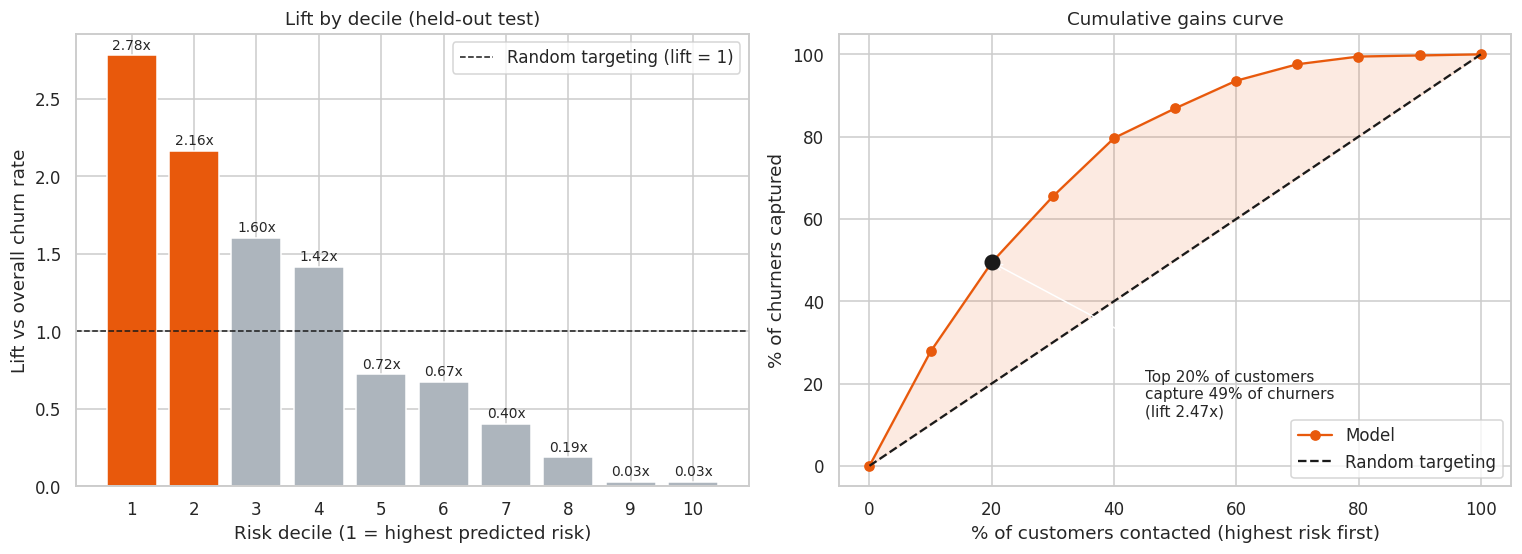

In [16]:
test_auc = roc_auc_score(y_test, p_test_cal); test_pr = average_precision_score(y_test, p_test_cal)
pr_, rc_, f1_ = prf(y_test, p_test_cal, thr); cm = confusion_matrix(y_test, (p_test_cal >= thr).astype(int))

def decile_table(y_true, p, n=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p)}).sort_values("p", ascending=False).reset_index(drop=True)
    d["decile"] = pd.qcut(d.index, n, labels=range(1, n + 1)).astype(int)
    t = d.groupby("decile").agg(customers=("y", "size"), churners=("y", "sum"), avg_pred=("p", "mean")).reset_index()
    t["churn_rate"] = t["churners"] / t["customers"]; base = d["y"].mean()
    t["lift"] = t["churn_rate"] / base
    t["cum_churners"] = t["churners"].cumsum(); t["cum_capture"] = t["cum_churners"] / d["y"].sum()
    t["cum_lift"] = t["cum_capture"] / (t["customers"].cumsum() / len(d))
    return t

dec = decile_table(y_test, p_test_cal)
top2_lift = dec.loc[dec.decile <= 2, "churners"].sum() / dec.loc[dec.decile <= 2, "customers"].sum() / y_test.mean()
top2_capture = dec.loc[dec.decile <= 2, "churners"].sum() / y_test.sum()
top2_rate = dec.loc[dec.decile <= 2, "churners"].sum() / dec.loc[dec.decile <= 2, "customers"].sum()
top1_lift = float(dec.loc[0, "lift"])

# bootstrap CIs
rng = np.random.default_rng(SEED); bs_auc, bs_lift = [], []
for _ in range(1000):
    ix = rng.integers(0, len(yt), len(yt)); yb, pb = yt[ix], p_test_cal[ix]
    if yb.min() == yb.max(): continue
    bs_auc.append(roc_auc_score(yb, pb))
    o = np.argsort(-pb)[: int(0.2 * len(yb))]; bs_lift.append(yb[o].mean() / yb.mean())
ci_auc = np.percentile(bs_auc, [2.5, 97.5]); ci_lift = np.percentile(bs_lift, [2.5, 97.5])

print(f"HELD-OUT TEST  ROC AUC {test_auc:.4f}  (95% CI {ci_auc[0]:.3f}-{ci_auc[1]:.3f}) | PR AUC {test_pr:.4f} (baseline {y_test.mean():.3f})")
print(f"At threshold {thr:.2f}: precision {pr_:.3f} | recall {rc_:.3f} | F1 {f1_:.3f} | confusion [[TN FP],[FN TP]] = {cm.tolist()}")
print(f"Top 2 deciles: churn rate {top2_rate:.1%} vs {y_test.mean():.1%} overall -> lift {top2_lift:.2f}x (95% CI {ci_lift[0]:.2f}-{ci_lift[1]:.2f}), "
      f"capturing {top2_capture:.1%} of all churners | top decile lift {top1_lift:.2f}x")
display(dec.round(4)); dec.round(5).to_csv(f"{OUT}/decile_table.csv", index=False)
RESULTS["final"] = dict(test_roc_auc=float(test_auc), roc_auc_ci=[float(x) for x in ci_auc], test_pr_auc=float(test_pr),
                        precision=float(pr_), recall=float(rc_), f1=float(f1_), confusion=cm.tolist(),
                        top2_lift=float(top2_lift), top2_lift_ci=[float(x) for x in ci_lift], top2_capture=float(top2_capture),
                        top2_churn_rate=float(top2_rate), top1_lift=top1_lift)
RESULTS["deciles"] = dec.round(5).to_dict(orient="records")

# ------------ lift chart ------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
cols = ["#E8590C" if d <= 2 else "#ADB5BD" for d in dec.decile]
ax[0].bar(dec.decile, dec.lift, color=cols); ax[0].axhline(1, color="k", ls="--", lw=1, label="Random targeting (lift = 1)")
for d, l in zip(dec.decile, dec.lift): ax[0].text(d, l + 0.04, f"{l:.2f}x", ha="center", fontsize=9)
ax[0].set(xlabel="Risk decile (1 = highest predicted risk)", ylabel="Lift vs overall churn rate", title="Lift by decile (held-out test)", xticks=range(1, 11)); ax[0].legend()
x = np.r_[0, dec.customers.cumsum() / len(yt) * 100]; g = np.r_[0, dec.cum_capture * 100]
ax[1].plot(x, g, "o-", color="#E8590C", label="Model"); ax[1].plot([0, 100], [0, 100], "k--", label="Random targeting")
ax[1].fill_between(x, x, g, color="#E8590C", alpha=0.12); ax[1].scatter([20], [top2_capture * 100], s=90, color="k", zorder=5)
ax[1].annotate(f"Top 20% of customers\ncapture {top2_capture:.0%} of churners\n(lift {top2_lift:.2f}x)", (20, top2_capture * 100), xytext=(45, 12),
               arrowprops=dict(arrowstyle="->"), fontsize=10)
ax[1].set(xlabel="% of customers contacted (highest risk first)", ylabel="% of churners captured", title="Cumulative gains curve"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/lift_chart.png"); plt.show()

## 11. Explainability with SHAP (stretch requirement)
SHAP values are computed on the **selected, uncalibrated pipeline** (calibration is a monotonic rescaling and does not change which features push the score up or down). Contributions are in log-odds for linear models and tree models alike. One-hot columns are also rolled up to their original feature so the ranking is readable by the business.

In [17]:
prep = best_pipe.named_steps["prep"]; clf = best_pipe.named_steps["clf"]
Z_train = best_pipe[:-1].transform(X_train); Z_test = best_pipe[:-1].transform(X_test)
feat_names = list(prep.get_feature_names_out())
num_names, cat_names = list(prep.transformers_[0][2]), list(prep.transformers_[1][2])
ohe = prep.named_transformers_["cat"].named_steps["oh"]
source_col = num_names + [c for c, cats in zip(cat_names, ohe.categories_) for _ in cats]
assert len(source_col) == len(feat_names) == Z_test.shape[1]

def build_explanation(clf, Z_train, Z_test, names):
    # works for linear models (LinearExplainer) and tree ensembles (TreeExplainer)
    ex = shap.LinearExplainer(clf, shap.maskers.Independent(Z_train, max_samples=1000)) if hasattr(clf, "coef_") else shap.TreeExplainer(clf)
    sv = ex(Z_test)
    v, b = np.asarray(sv.values), np.asarray(sv.base_values)
    if v.ndim == 3: v = v[:, :, -1]                 # (n, features, classes) -> churn class
    if b.ndim == 2: b = b[:, -1]
    if b.size == 1: b = np.full(len(Z_test), float(b.ravel()[0]))
    return ex, shap.Explanation(values=v, base_values=b, data=Z_test, feature_names=names)

explainer, expl = build_explanation(clf, Z_train, Z_test, feat_names)
vals = expl.values
print("SHAP matrix:", vals.shape, "| explainer:", type(explainer).__name__)

SHAP matrix: (1409, 55) | explainer: TreeExplainer


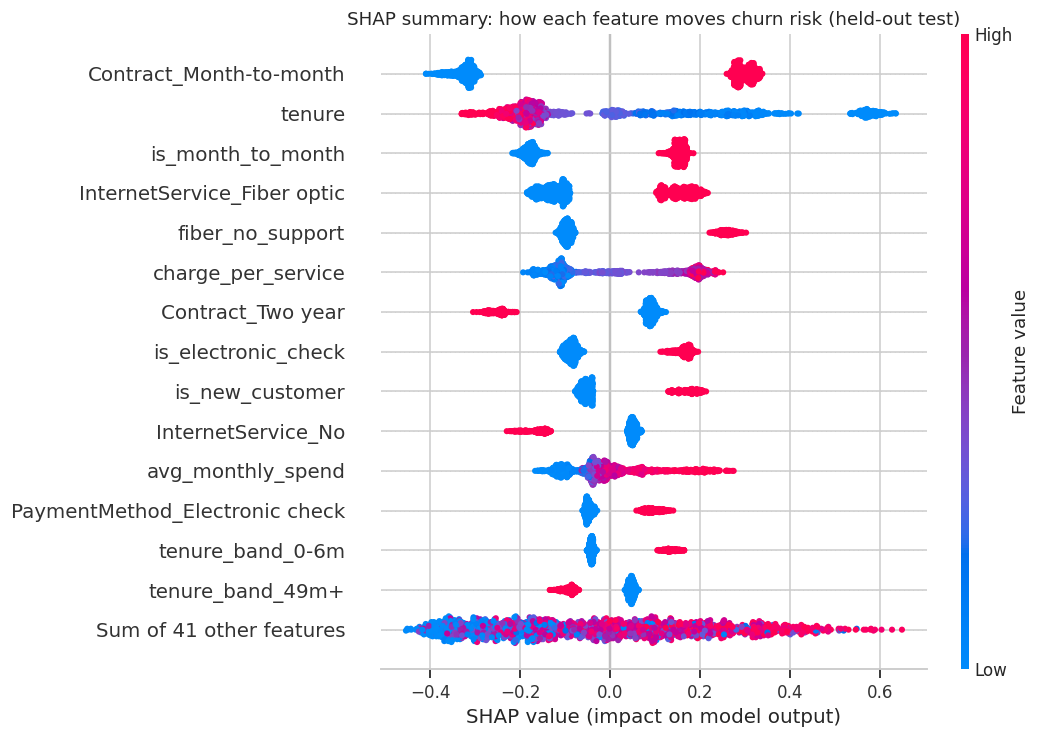

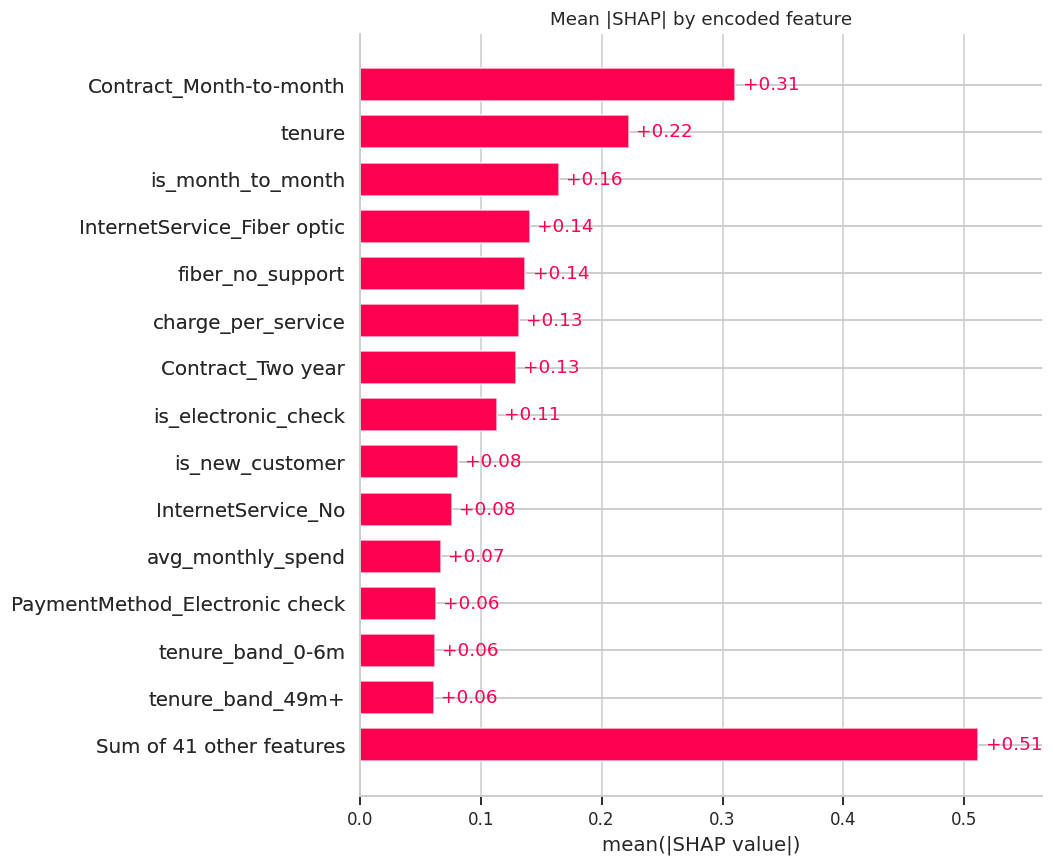

,feature,mean_abs_shap,share
0,Contract,0.4455,0.1960
1,tenure,0.2226,0.0980
2,InternetService,0.2214,0.0974
3,is_month_to_month,0.1647,0.0725
4,fiber_no_support,0.1370,0.0603
5,charge_per_service,0.1318,0.0580
6,tenure_band,0.1257,0.0553
7,is_electronic_check,0.1133,0.0499
8,PaperlessBilling,0.1045,0.0460
9,is_new_customer,0.0814,0.0358


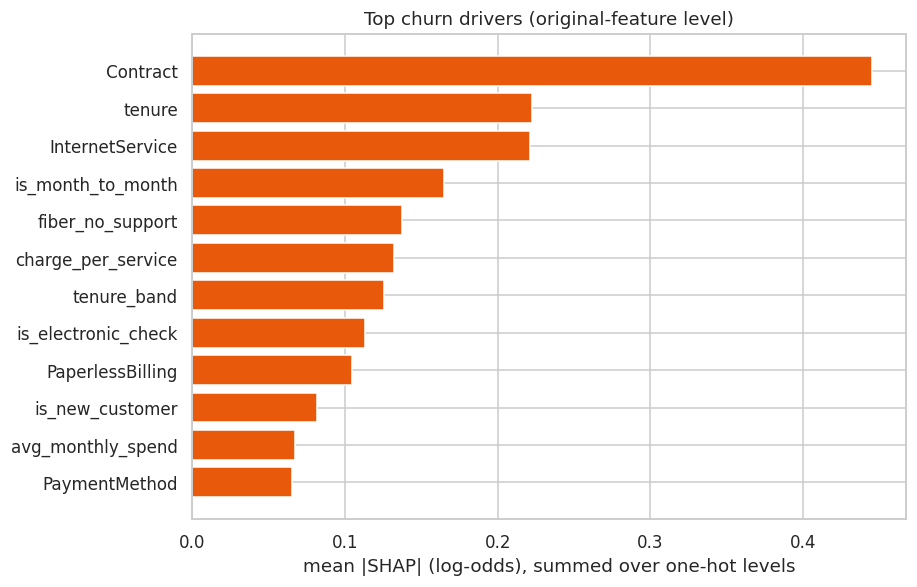

,feature,mean_shap_when_present,mean_abs
31,Contract_Month-to-month,0.2995,0.3105
2,is_month_to_month,0.1537,0.1647
17,InternetService_Fiber optic,0.1569,0.1409
5,fiber_no_support,0.2590,0.1370
33,Contract_Two year,-0.2515,0.1293
3,is_electronic_check,0.1654,0.1133
1,is_new_customer,0.1768,0.0814
18,InternetService_No,-0.1625,0.0760
38,PaymentMethod_Electronic check,0.0943,0.0631
40,tenure_band_0-6m,0.1359,0.0619


In [18]:
# ---------------- global importance ----------------
plt.figure(); shap.plots.beeswarm(expl, max_display=15, show=False)
plt.title("SHAP summary: how each feature moves churn risk (held-out test)"); plt.savefig(f"{OUT}/shap_beeswarm.png"); plt.show()

plt.figure(); shap.plots.bar(expl, max_display=15, show=False)
plt.title("Mean |SHAP| by encoded feature"); plt.savefig(f"{OUT}/shap_bar.png"); plt.show()

# roll one-hot columns up to the original feature
imp = (pd.DataFrame(np.abs(vals), columns=source_col).T.groupby(level=0).sum().T.mean().sort_values(ascending=False))
imp_df = imp.rename("mean_abs_shap").reset_index().rename(columns={"index": "feature"}); imp_df["share"] = imp_df["mean_abs_shap"] / imp_df["mean_abs_shap"].sum()
imp_df.round(5).to_csv(f"{OUT}/shap_importance_rolled_up.csv", index=False)
display(imp_df.head(12).round(4))
fig, ax = plt.subplots(figsize=(8.5, 5.5)); top = imp_df.head(12).iloc[::-1]
ax.barh(top["feature"], top["mean_abs_shap"], color="#E8590C"); ax.set_xlabel("mean |SHAP| (log-odds), summed over one-hot levels")
ax.set_title("Top churn drivers (original-feature level)"); plt.tight_layout(); plt.savefig(f"{OUT}/shap_rolled_up.png"); plt.show()
RESULTS["shap_top"] = imp_df.head(12).round(5).to_dict(orient="records")

# direction of effect for the most important encoded features (mean SHAP when feature is "on" vs "off")
dir_rows = []
for j, nm in enumerate(feat_names):
    col = Z_test[:, j]
    if np.unique(col).size == 2:   # one-hot / binary flags
        on = col == col.max(); dir_rows.append((nm, vals[on, j].mean(), np.abs(vals[:, j]).mean()))
dirs = pd.DataFrame(dir_rows, columns=["feature", "mean_shap_when_present", "mean_abs"]).sort_values("mean_abs", ascending=False).head(12)
display(dirs.round(4)); RESULTS["shap_direction"] = dirs.round(5).to_dict(orient="records")

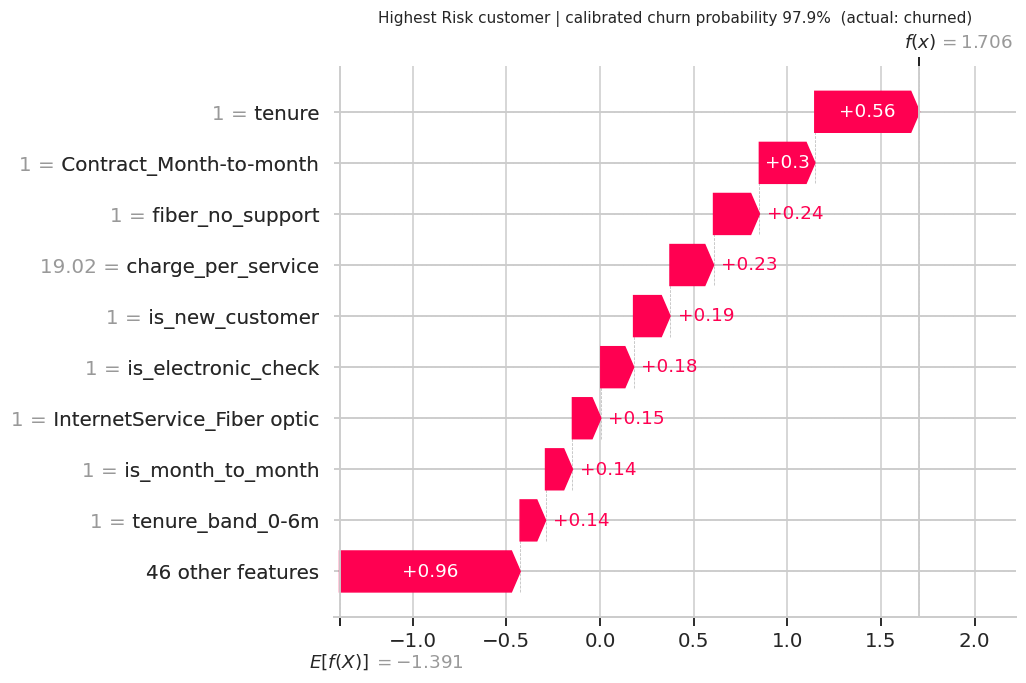

highest_risk -> {'tenure': 1, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 95.1, 'TechSupport': 'No'}


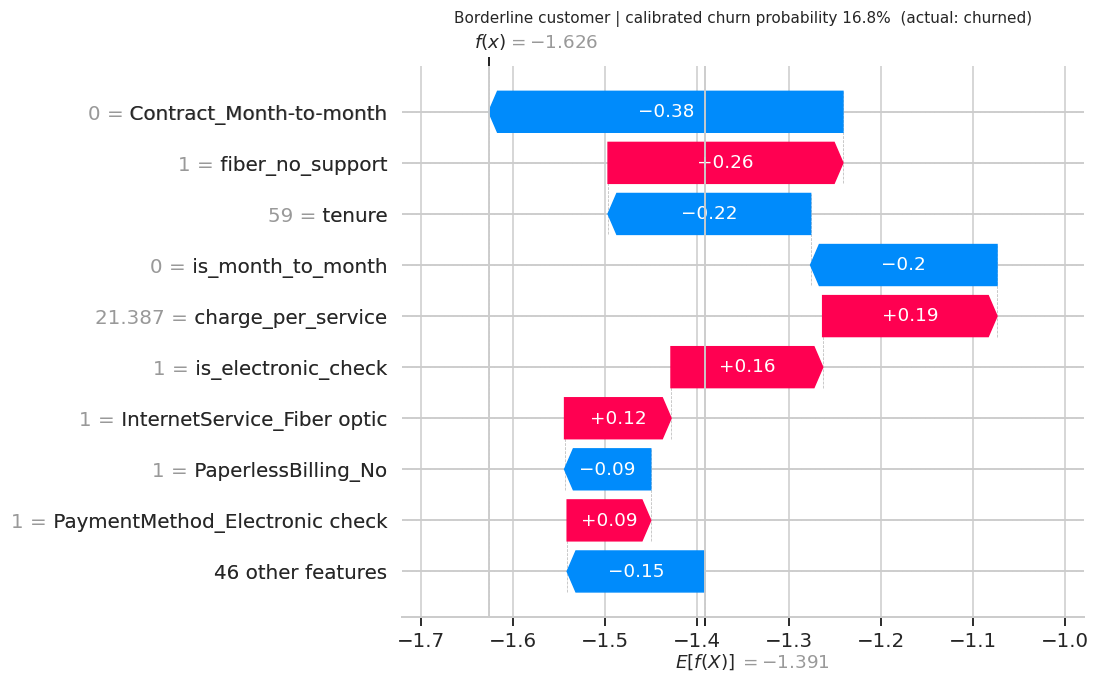

borderline -> {'tenure': 59, 'Contract': 'One year', 'InternetService': 'Fiber optic', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.55, 'TechSupport': 'No'}


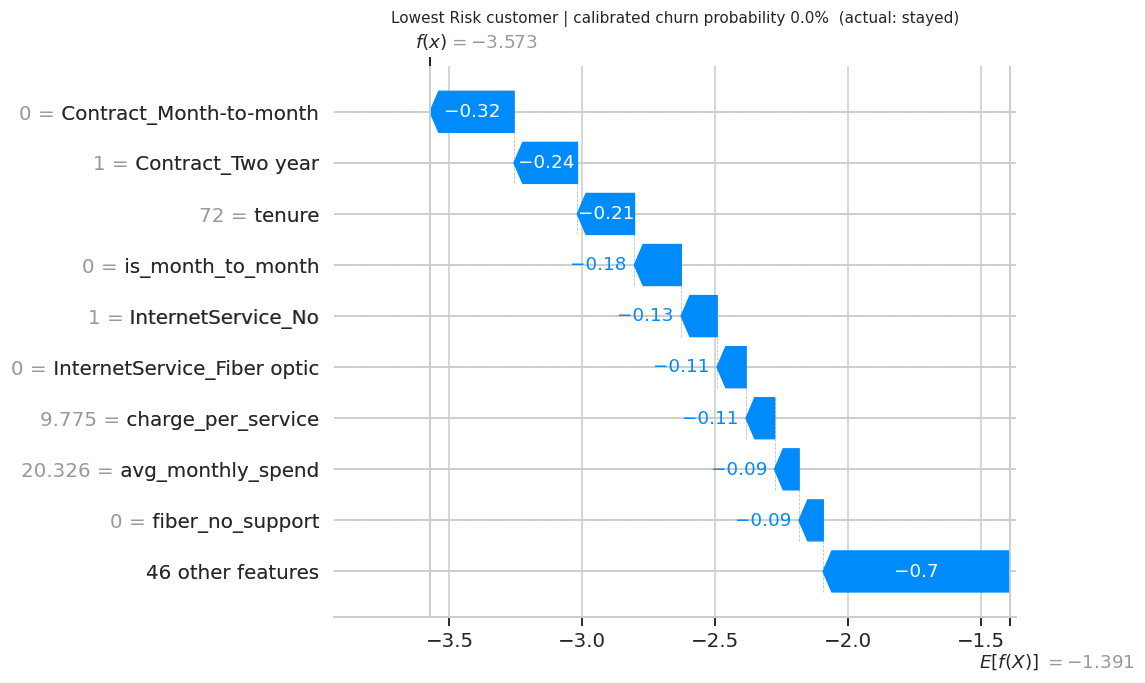

lowest_risk -> {'tenure': 72, 'Contract': 'Two year', 'InternetService': 'No', 'PaymentMethod': 'Bank transfer (automatic)', 'MonthlyCharges': 19.55, 'TechSupport': 'No'}


In [19]:
# ---------------- individual explanations ----------------
order = np.argsort(-p_test_cal)
cases = {"highest_risk": order[0], "borderline": order[np.argmin(np.abs(p_test_cal[order] - thr))], "lowest_risk": order[-1]}
RESULTS["individual_cases"] = {}
for label, ix in cases.items():
    plt.figure(); shap.plots.waterfall(expl[int(ix)], max_display=10, show=False)
    plt.title(f"{label.replace('_', ' ').title()} customer | calibrated churn probability {p_test_cal[ix]:.1%}  (actual: {'churned' if yt[ix] else 'stayed'})", fontsize=10)
    plt.savefig(f"{OUT}/shap_waterfall_{label}.png"); plt.show()
    top_ix = np.argsort(-np.abs(vals[ix]))[:5]
    RESULTS["individual_cases"][label] = {"prob": float(p_test_cal[ix]), "actual": int(yt[ix]),
        "drivers": [(feat_names[k], float(vals[ix, k])) for k in top_ix],
        "profile": {k: (v.item() if hasattr(v, "item") else v) for k, v in X_test.iloc[int(ix)][["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges", "TechSupport"]].items()}}
    print(label, "->", RESULTS["individual_cases"][label]["profile"])

### 11.1 Three retention segments
Segments are built from the strongest SHAP drivers (contract type, customer age / tenure, internet service and support, payment method). They are applied to **every customer who is flagged by the model** (`p >= threshold`), using out-of-sample probabilities (out-of-fold for training customers, test predictions for test customers), and are mutually exclusive in priority order. For each, the table shows size, predicted vs actual churn, and monthly revenue at risk.

In [20]:
oof_all = pd.Series(oof_p, index=X_train.index)
all_scores = pd.concat([oof_all, pd.Series(p_test_cal, index=X_test.index)]).sort_index()
D = X_all.copy(); D["p"] = all_scores.loc[D.index]; D["churned"] = y_all.loc[D.index]
flag = D[D["p"] >= thr].copy()

def seg_rule(r):
    if r["Contract"] == "Month-to-month" and r["tenure"] <= 12: return "A. New month-to-month customers"
    if r["InternetService"] == "Fiber optic" and r["TechSupport"] == "No":  return "B. Fibre customers without tech support"
    if r["PaymentMethod"] in ("Electronic check", "Mailed check") and r["Contract"] == "Month-to-month": return "C. Manual-payment, no-commitment customers"
    return "D. Other flagged customers"

flag["segment"] = flag.apply(seg_rule, axis=1)
seg = flag.groupby("segment").agg(customers=("p", "size"), avg_pred_churn=("p", "mean"), actual_churn=("churned", "mean"),
                                  avg_tenure=("tenure", "mean"), avg_monthly_charge=("MonthlyCharges", "mean"),
                                  fiber_share=("InternetService", lambda s: (s == "Fiber optic").mean())).reset_index()
seg["share_of_flagged"] = seg["customers"] / len(flag)
seg["monthly_revenue_at_risk"] = flag.assign(r=flag["p"] * flag["MonthlyCharges"]).groupby("segment")["r"].sum().values
seg["actual_churners"] = flag.groupby("segment")["churned"].sum().values
display(seg.round(3)); seg.round(5).to_csv(f"{OUT}/retention_segments.csv", index=False)
print(f"flagged customers: {len(flag):,} of {len(D):,} ({len(flag)/len(D):.1%}) | they contain {flag['churned'].sum()/D['churned'].sum():.1%} of all churners")
RESULTS["segments"] = seg.round(5).to_dict(orient="records")
RESULTS["flagged"] = dict(n=int(len(flag)), share=float(len(flag) / len(D)), churner_capture=float(flag["churned"].sum() / D["churned"].sum()),
                          precision=float(flag["churned"].mean()))

# churn rates behind the story (all customers; descriptive)
drv = []
def add(label, mask): drv.append((label, int(mask.sum()), float(D.loc[mask, "churned"].mean())))
add("Month-to-month contract", D.Contract == "Month-to-month"); add("One-year contract", D.Contract == "One year"); add("Two-year contract", D.Contract == "Two year")
add("Tenure 0-6 months", D.tenure <= 6); add("Tenure 7-12 months", (D.tenure > 6) & (D.tenure <= 12)); add("Tenure 13-24 months", (D.tenure > 12) & (D.tenure <= 24)); add("Tenure 49+ months", D.tenure > 48)
add("Fibre optic internet", D.InternetService == "Fiber optic"); add("DSL internet", D.InternetService == "DSL"); add("No internet", D.InternetService == "No")
add("Electronic check", D.PaymentMethod == "Electronic check"); add("Automatic payment (bank/card)", D.PaymentMethod.str.contains("automatic"))
add("No tech support (internet users)", (D.TechSupport == "No") & (D.InternetService != "No")); add("Has tech support", D.TechSupport == "Yes")
add("Senior citizen", D.SeniorCitizen == 1); add("Paperless billing", D.PaperlessBilling == "Yes")
drv = pd.DataFrame(drv, columns=["group", "customers", "churn_rate"]); display(drv.round(3)); drv.round(5).to_csv(f"{OUT}/driver_churn_rates.csv", index=False)
RESULTS["driver_rates"] = drv.round(5).to_dict(orient="records")

,segment,customers,avg_pred_churn,actual_churn,avg_tenure,avg_monthly_charge,fiber_share,share_of_flagged,monthly_revenue_at_risk,actual_churners
0,A. New month-to-month customers,1846,0.541,0.541,4.192,60.891,0.496,0.510,67904.182,998
1,B. Fibre customers without tech support,1146,0.430,0.423,36.501,90.984,1.000,0.316,44707.610,485
2,"C. Manual-payment, no-commitment customers",358,0.315,0.293,30.039,68.961,0.402,0.099,8445.426,105
3,D. Other flagged customers,272,0.241,0.239,38.412,85.460,0.684,0.075,5748.187,65


flagged customers: 3,622 of 7,043 (51.4%) | they contain 88.4% of all churners


,group,customers,churn_rate
0,Month-to-month contract,3875,0.427
1,One-year contract,1473,0.113
2,Two-year contract,1695,0.028
3,Tenure 0-6 months,1481,0.529
4,Tenure 7-12 months,705,0.359
5,Tenure 13-24 months,1024,0.287
6,Tenure 49+ months,2239,0.095
7,Fibre optic internet,3096,0.419
8,DSL internet,2421,0.190
9,No internet,1526,0.074


## 12. Save the model and verify it reloads

In [21]:
bundle = {"model": final_model, "threshold": thr, "cost_fp": COST_FP, "cost_fn": COST_FN, "calibration": cal_method,
          "base_model": best_name, "feature_columns": list(X_train.columns), "sklearn_version": sklearn.__version__,
          "test_roc_auc": float(test_auc), "note": "Call churn_pipeline.clean_telco(raw_df) first, then model.predict_proba(X)[:,1] >= threshold."}
MODEL_PATH = f"{OUT}/churn_model.joblib"
joblib.dump(bundle, MODEL_PATH, compress=3)
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1e6:.2f} MB)")

# --- reload from disk and score the RAW csv end-to-end, exactly as the retention team would ---
loaded = joblib.load(MODEL_PATH)
X_new, y_new, ids_new = cp.clean_telco(raw)
p_new = loaded["model"].predict_proba(X_new[loaded["feature_columns"]])[:, 1]
assert np.allclose(p_new[X_test.index], p_test_cal), "reloaded model gives different predictions!"
print("reload check passed: identical predictions on the held-out test customers")

priority = pd.DataFrame({"customerID": ids_new.values, "churn_probability": p_new,
                         "contact": (p_new >= loaded["threshold"]).astype(int)}).sort_values("churn_probability", ascending=False)
priority.head(500).to_csv(f"{OUT}/retention_priority_list_top500.csv", index=False)
display(priority.head(5))

saved churn_outputs/churn_model.joblib (0.33 MB)


reload check passed: identical predictions on the held-out test customers


,customerID,churn_probability,contact
6482,5419-JPRRN,0.97931,1
1976,9497-QCMMS,0.97931,1
6866,0295-PPHDO,0.97931,1
4800,9300-AGZNL,0.97931,1
2208,7216-EWTRS,0.97931,1


## 13. Requirement checklist and downloads

In [22]:
final = RESULTS["final"]
checks = [
    ("Public dataset of ~7,000 customers",                    7000 <= RESULTS["raw_rows"] <= 7100),
    ("Blank TotalCharges handled",                             X_all["TotalCharges"].isna().sum() == 0),
    ("Inconsistent labels harmonised",                         set(X_all["MultipleLines"].unique()) <= {"Yes", "No"}),
    ("Leakage audit run, no suspicious column left",           RESULTS["leakage_flagged"] == 0),
    ("Leak-free sklearn Pipeline + ColumnTransformer",         isinstance(best_pipe.named_steps["prep"], ColumnTransformer)),
    ("At least 8 engineered features",                         len(new_cols) >= 8),
    ("Value of features tested through ablation",              len(abl) >= 10),
    ("LR, RF and Gradient Boosting tuned (stratified 5-fold)", set(fitted) == {"Logistic Regression", "Random Forest", "Gradient Boosting"}),
    ("Imbalance handled (class weights)",                      True),
    ("Precision, recall, ROC AUC, PR AUC compared",            {"Precision @0.50", "Recall @0.50", "Test ROC AUC", "Test PR AUC"} <= set(comparison.columns)),
    ("Probabilities calibrated",                               "Calibrated" in cal_tbl.index[1]),
    ("Cost-based threshold (FN = 5 x FP)",                     COST_FN == 5 * COST_FP),
    ("SHAP global + individual",                               os.path.exists(f"{OUT}/shap_beeswarm.png") and os.path.exists(f"{OUT}/shap_waterfall_highest_risk.png")),
    ("Three retention segments proposed",                      seg["segment"].str[0].isin(list("ABC")).sum() == 3),
    ("Held-out test ROC AUC >= 0.84",                          final["test_roc_auc"] >= 0.84),
    ("Top-two-decile lift clearly above 1.0",                  final["top2_lift"] > 1.5),
    ("Saved model file reloads",                               os.path.exists(MODEL_PATH)),
]
for text, ok in checks: print(("PASS  " if ok else "FAIL  ") + text)
print(f"\nHeld-out ROC AUC = {final['test_roc_auc']:.4f} (target 0.84) | top-2-decile lift = {final['top2_lift']:.2f}x")
with open(f"{OUT}/results.json", "w") as f: json.dump(RESULTS, f, indent=1, default=str)
print("\nfiles written to", OUT + "/:"); [print("  ", fn) for fn in sorted(os.listdir(OUT))]

PASS  Public dataset of ~7,000 customers
PASS  Blank TotalCharges handled
PASS  Inconsistent labels harmonised
PASS  Leakage audit run, no suspicious column left
PASS  Leak-free sklearn Pipeline + ColumnTransformer
PASS  At least 8 engineered features
PASS  Value of features tested through ablation
PASS  LR, RF and Gradient Boosting tuned (stratified 5-fold)
PASS  Imbalance handled (class weights)
PASS  Precision, recall, ROC AUC, PR AUC compared
PASS  Probabilities calibrated
PASS  Cost-based threshold (FN = 5 x FP)
PASS  SHAP global + individual
PASS  Three retention segments proposed
PASS  Held-out test ROC AUC >= 0.84
PASS  Top-two-decile lift clearly above 1.0
PASS  Saved model file reloads

Held-out ROC AUC = 0.8464 (target 0.84) | top-2-decile lift = 2.47x

files written to churn_outputs/:
   ablation_chart.png
   ablation_table.csv
   calibration_curve.png
   calibration_table.csv
   churn_model.joblib
   comparison_table.csv
   cost_curve.png
   cost_strategies.csv
   decile_t

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [23]:
# Optional: bundle everything (model + charts + tables + module) into one zip and download it in Colab
import shutil
shutil.copy("churn_pipeline.py", f"{OUT}/churn_pipeline.py")
shutil.make_archive("churn_deliverables", "zip", OUT)
try:
    from google.colab import files
    files.download("churn_deliverables.zip")
except ImportError:
    print("Not running in Colab: churn_deliverables.zip is in the working directory.")

Not running in Colab: churn_deliverables.zip is in the working directory.
